<a href="https://colab.research.google.com/github/iamnushfaa/dhaka-rainfall-analysis/blob/main/Dhaka_Rainfall_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Rainfall Variability in Dhaka (1981-2023)
Goal: clean NASA POWER daily rainfall data and examine monthly and annual patterns.

In [1]:
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
url = "https://power.larc.nasa.gov/api/temporal/daily/point"
params = {
    "parameters": "PRECTOTCORR",   # corrected precipitation, mm/day
    "community": "AG",
    "longitude": 90.41,            # Dhaka
    "latitude": 23.81,
    "start": "19810101",
    "end": "20231231",
    "format": "JSON",
}
r = requests.get(url, params=params, timeout=120)
r.raise_for_status()
raw = r.json()["properties"]["parameter"]["PRECTOTCORR"]

In [3]:
df = pd.DataFrame(list(raw.items()), columns=["date", "rain_mm"])
df["date"] = pd.to_datetime(df["date"], format="%Y%m%d")
df = df.set_index("date")

df.head()
df.describe()
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 15705 entries, 1981-01-01 to 2023-12-31
Data columns (total 1 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   rain_mm  15705 non-null  float64
dtypes: float64(1)
memory usage: 245.4 KB


In [4]:
df["rain_mm"] = df["rain_mm"].replace(-999, np.nan)
print("Missing days:", df["rain_mm"].isna().sum())

Missing days: 0


In [5]:
monthly = df["rain_mm"].resample("MS").sum(min_count=1)   # total per month
annual = df["rain_mm"].resample("YS").sum(min_count=1)    # total per year
climatology = monthly.groupby(monthly.index.month).mean() # average per calendar month

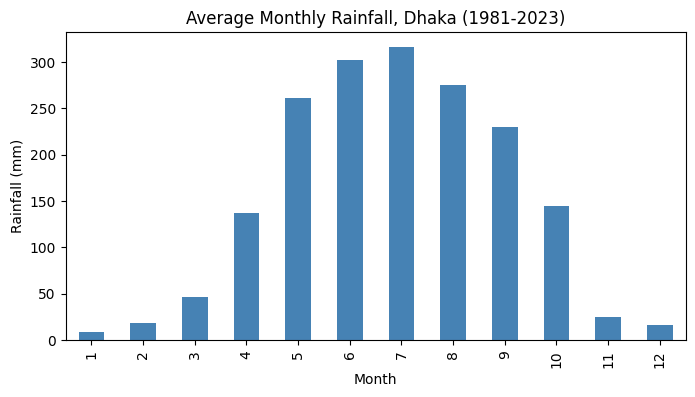

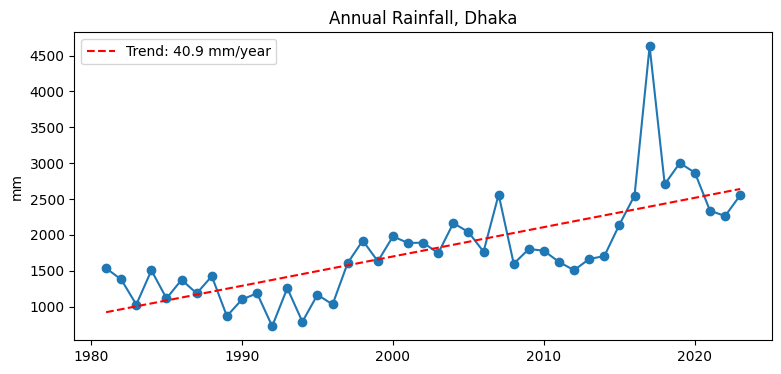

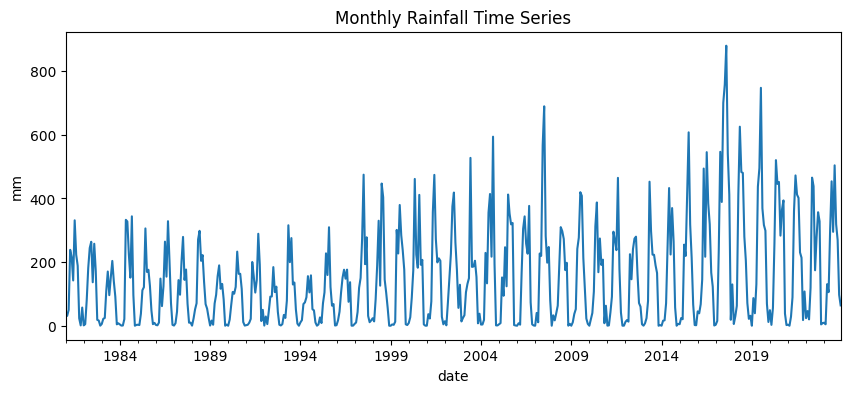

In [6]:
# 1. Seasonal cycle
climatology.plot(kind="bar", figsize=(8,4), color="steelblue")
plt.title("Average Monthly Rainfall, Dhaka (1981-2023)")
plt.xlabel("Month"); plt.ylabel("Rainfall (mm)")
plt.show()

# 2. Annual totals with a trend line
years = annual.index.year
plt.figure(figsize=(9,4))
plt.plot(years, annual.values, marker="o")
slope, intercept = np.polyfit(years, annual.values, 1)
plt.plot(years, slope*years + intercept, "r--", label=f"Trend: {slope:.1f} mm/year")
plt.title("Annual Rainfall, Dhaka"); plt.ylabel("mm"); plt.legend()
plt.show()

# 3. Full monthly time series
monthly.plot(figsize=(10,4))
plt.title("Monthly Rainfall Time Series"); plt.ylabel("mm")
plt.show()

## Interpretation

**Seasonal pattern.** Rainfall in Dhaka is strongly seasonal. Average monthly rainfall peaks in July (about 315 mm), with June and August also high, and the wet period runs from May to October, which accounts for roughly 85% of the average annual total. The dry months, December to February, receive under about 20 mm each. This matches the South Asian summer monsoon, when moist southwesterly flow from the Bay of Bengal brings most of Bangladesh's rainfall.

**Long-term variability and trend.** Annual rainfall shows an upward linear trend of about 41 mm/year (1981-2023). However, this should be interpreted with caution. The trend is strongly influenced by a single extreme year (2017, around 4,600 mm), and year-to-year variability is large relative to the trend. The monthly time series also shows higher peak values after the late 1990s, which could reflect real change, natural multi-decadal variability, or changes in the inputs used to build the dataset. I did not test the trend for statistical significance, so I cannot conclude that rainfall in Dhaka is increasing.

**Limitations.**
- The data is from a single grid point (about 0.5° resolution), so it represents an area average, not a station measurement in Dhaka city.
- NASA POWER rainfall is derived from satellite observations and reanalysis models, so it may contain biases, especially for extreme events.
- 43 years is a relatively short record for separating climate trends from natural variability.

**Next steps.** I would validate these results against Bangladesh Meteorological Department station data, test the trend's significance (for example with a Mann-Kendall test), and check how sensitive it is to the 2017 outlier.